# モデル3の解析: 模倣学習の集団で、何が「有名」になるか

モデル3では、全員が均等配分から始め、隣人の成功を見て配分をまねます(フェルミ則 + 突然変異)。
このノートでは、次の順に解析します。

1. **行き先**: 集団はどの状態に落ち着き、いつ移るか
2. **有名人の戦略の推移**: 各時点で有名な人(次数上位10%)は、集団より先に新しい戦略を使っているか
3. **戦略タイプ別の成績**: アウトリーチ型や研究型の有利さは、集団での割合でどう変わるか
4. **最終的な有名人の軌跡**: 最後に有名になった人は、いつ戦略を乗り換えたか
5. **勝った戦略の系譜**: 最後に集団を占めた戦略は、いつ、どこから生まれ、どう広がったか
6. **最終状態のネットワーク**

計算は `python3 src/model3_compute.py [シード数] [ステップ数]` で行い、結果は `results/model3/` に保存されます。このノートは保存済みの結果を読み込むだけです。

**記号の約束**
- 「有名さ」は次数です。評価窓(50ステップ)の平均次数を使います。
- 記録は評価窓ごとです。k 番目の窓の平均次数 `D[k]` は、その窓の間に使っていた配分 `X[k-1]` の成績です。
- **アウトリーチ型**はアウトリーチ割合が0.6以上、**研究型**は研究割合が0.6以上の人です。どちらでもない人は**混合型**とします。

In [1]:
import os, sys, glob
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
sys.path.insert(0, os.path.abspath('../src'))
from sim import DEFAULT
from model3_tools import lineage

R3 = '../results/model3'
runs = [dict(np.load(f)) for f in sorted(glob.glob(f'{R3}/run_*.npz'))]
TAU = DEFAULT['tau']
for r in runs:
    r['X'] = r['X'].astype(float); r['D'] = r['D'].astype(float)
n_rec = runs[0]['X'].shape[0]
steps = np.arange(n_rec) * TAU
print('seeds:', len(runs), ' records per seed:', n_rec, ' steps:', steps[-1])

# 色と頂点ラベル (他の図と同じ仕様)
LC = {'acquaint': 'tab:blue', 'research': 'tab:orange', 'outreach': 'tab:green'}
KEYS = ['acquaint', 'research', 'outreach']
NAMES = {'acquaint': 'r1 acquaint.', 'research': 'r2 research', 'outreach': 'r3 outreach'}
LABEL_SIZE = 16

def tern(x):
    x = np.atleast_2d(x); return x[:, 1] + 0.5 * x[:, 2], np.sqrt(3) / 2 * x[:, 2]

def tri_axes(ax, title=''):
    ax.plot([0, 1, 0.5, 0], [0, 0, np.sqrt(3)/2, 0], 'k-', lw=0.8)
    ax.text(0, -0.04, NAMES['acquaint'], ha='center', va='top', fontsize=LABEL_SIZE, color=LC['acquaint'])
    ax.text(1, -0.04, NAMES['research'], ha='center', va='top', fontsize=LABEL_SIZE, color=LC['research'])
    ax.text(0.5, np.sqrt(3)/2 + 0.03, NAMES['outreach'], ha='center', va='bottom', fontsize=LABEL_SIZE, color=LC['outreach'])
    ax.set_xlim(-0.25, 1.25); ax.set_ylim(-0.2, np.sqrt(3)/2 + 0.2)
    if title: ax.set_title(title, fontsize=12)
    ax.set_aspect('equal'); ax.axis('off')

def strat_legend(ax, **kw):
    ax.legend(handles=[Line2D([], [], color=LC[k], label=NAMES[k]) for k in KEYS], **kw)

def types(x):
    """0 = 混合型, 1 = 研究型, 2 = アウトリーチ型"""
    t = np.zeros(x.shape[:-1], int)
    t[x[..., 1] >= 0.6] = 1; t[x[..., 2] >= 0.6] = 2
    return t
TYPE_NAMES = ['mixed', 'research type', 'outreach type']
TYPE_COLORS = ['gray', LC['research'], LC['outreach']]

seeds: 16  records per seed: 241  steps: 12000


## 1. 行き先: 集団はどこに落ち着き、いつ移るか

集団平均でアウトリーチ割合が0.5を超えたらアウトリーチ型の状態、研究割合が0.5を超えたら研究型の状態とします。
**移行時刻**は、集団平均のアウトリーチ割合(または研究割合)が初めて0.5を超えた時刻です。

In [2]:
rows = []
for s, r in enumerate(runs):
    pm = r['X'].mean(1)                      # 集団平均の配分 (時刻 x 3)
    fin = pm[-20:].mean(0)                   # 最後の1000ステップの平均
    state = 'outreach' if fin[2] > 0.5 else 'research' if fin[1] > 0.5 else 'mixed'
    k = {'outreach': 2, 'research': 1}.get(state)
    cross = np.argmax(pm[:, k] > 0.5) if k is not None else -1
    r['state'], r['t_cross'] = state, cross
    rows.append(dict(seed=s, state=state, x1=fin[0], x2=fin[1], x3=fin[2],
                     transition_step=steps[cross] if cross >= 0 else np.nan,
                     final_mean_degree=r['D'][-20:].mean()))
out = pd.DataFrame(rows).round(2)
display(out)
print(out['state'].value_counts().to_string())
print(out.groupby('state')[['final_mean_degree', 'transition_step']].mean().round(1))

,seed,state,x1,x2,x3,transition_step,final_mean_degree
0,0,outreach,0.16,0.04,0.80,2600,12.80
1,1,outreach,0.13,0.03,0.84,1450,13.03
2,2,research,0.24,0.71,0.05,1800,11.07
3,3,outreach,0.15,0.04,0.81,4300,12.75
4,4,research,0.30,0.65,0.05,1500,10.86
5,5,research,0.24,0.71,0.04,2050,11.06
6,6,outreach,0.15,0.04,0.82,2550,12.97
7,7,outreach,0.15,0.04,0.81,3600,12.71
8,8,outreach,0.14,0.03,0.83,2500,12.81
9,9,outreach,0.16,0.05,0.79,1200,12.82


outreach    12
research     4
          final_mean_degree  transition_step
state                                       
outreach               12.8           2670.8
research               10.9           1787.5


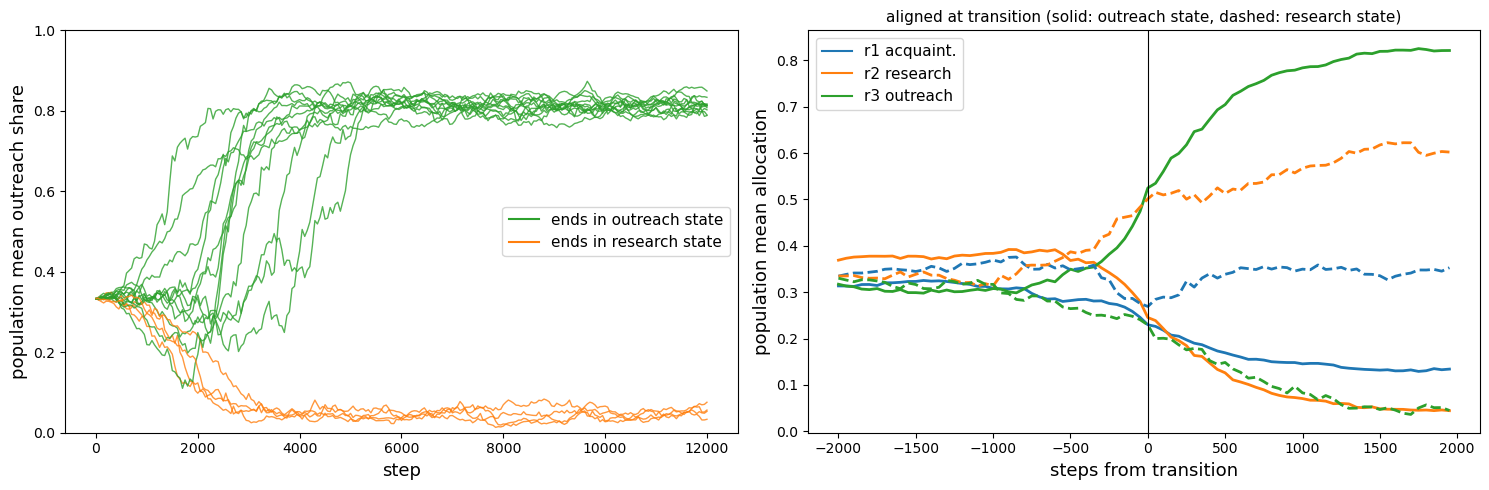

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for r in runs:
    pm = r['X'].mean(1)
    col = LC['outreach'] if r['state'] == 'outreach' else LC['research'] if r['state'] == 'research' else 'gray'
    axs[0].plot(steps, pm[:, 2], color=col, lw=1, alpha=0.8)
axs[0].set_xlabel('step', fontsize=13); axs[0].set_ylabel('population mean outreach share', fontsize=13)
axs[0].legend(handles=[Line2D([], [], color=LC['outreach'], label='ends in outreach state'),
                       Line2D([], [], color=LC['research'], label='ends in research state')], fontsize=11)
axs[0].set_ylim(0, 1)
# 移行の前後をそろえて重ねる: 移行時刻を 0 にした集団平均の配分
for st, ls in (('outreach', '-'), ('research', '--')):
    al = [r for r in runs if r['state'] == st]
    if not al: continue
    w = 40
    seg = np.array([r['X'].mean(1)[max(r['t_cross'] - w, 0):r['t_cross'] + w] for r in al
                    if r['t_cross'] - w >= 0 and r['t_cross'] + w <= n_rec])
    if len(seg) == 0: continue
    tt = (np.arange(-w, w)) * TAU
    for k, key in enumerate(KEYS):
        axs[1].plot(tt, seg[:, :, k].mean(0), color=LC[key], ls=ls, lw=2)
axs[1].axvline(0, color='k', lw=0.8)
axs[1].set_xlabel('steps from transition', fontsize=13); axs[1].set_ylabel('population mean allocation', fontsize=13)
axs[1].set_title('aligned at transition (solid: outreach state, dashed: research state)', fontsize=11)
strat_legend(axs[1], fontsize=11)
plt.tight_layout(); plt.show()

## 2. 有名人の戦略の推移

各時点で、窓平均の次数が上位10%の人を「その時点の有名人」とします。有名人の配分と集団平均を比べ、有名人が集団より先に新しい戦略へ移っているかを見ます。
右の図は、移行時刻をそろえてシードを平均したものです。

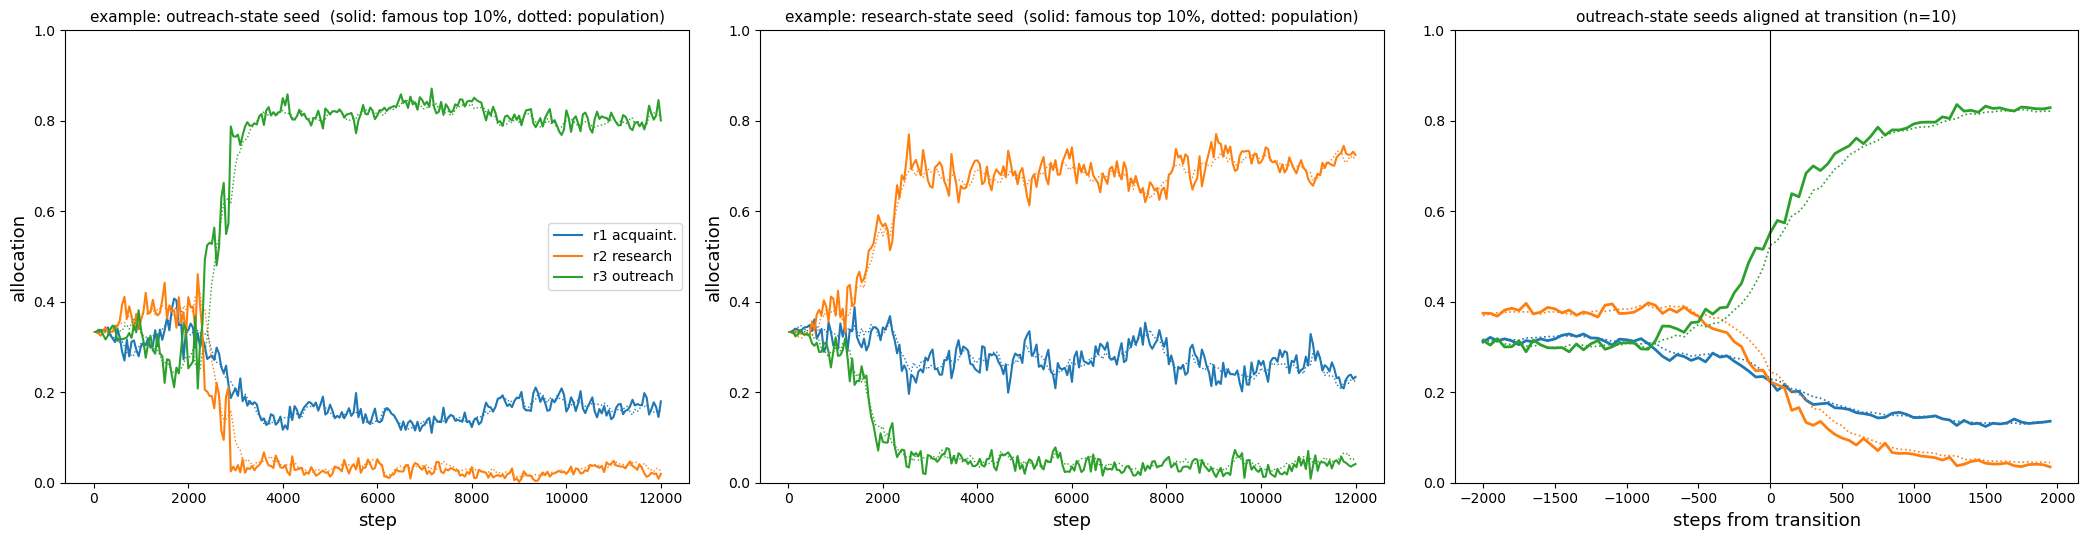

famous people cross outreach share 0.5 earlier than the population by (steps): [200, 150, 700, 100, 300, 200, 400, 150, 100, 500, 100, 150]
median lead: 175.0


In [4]:
def famous_alloc(r, q=0.9):
    """各時点の有名人(上位10%)の平均配分。D[k] の成績を生んだ配分 X[k-1] を使う"""
    X, D = r['X'][:-1], r['D'][1:]
    thr = np.quantile(D, q, axis=1, keepdims=True)
    m = D >= thr
    return np.array([X[k][m[k]].mean(0) for k in range(len(X))])

for r in runs:
    r['F'] = famous_alloc(r)

ex_o = next(r for r in runs if r['state'] == 'outreach')
ex_r = next((r for r in runs if r['state'] == 'research'), None)
fig, axs = plt.subplots(1, 3, figsize=(21, 5.5))
for ax, r, ttl in ((axs[0], ex_o, 'example: outreach-state seed'), (axs[1], ex_r, 'example: research-state seed')):
    if r is None: ax.axis('off'); continue
    for k, key in enumerate(KEYS):
        ax.plot(steps[1:], r['F'][:, k], color=LC[key], lw=1.5)
        ax.plot(steps, r['X'].mean(1)[:, k], color=LC[key], lw=1, ls=':')
    ax.set_title(ttl + '  (solid: famous top 10%, dotted: population)', fontsize=11)
    ax.set_xlabel('step', fontsize=13); ax.set_ylabel('allocation', fontsize=13); ax.set_ylim(0, 1)
strat_legend(axs[0], fontsize=10, loc='center right')

# 移行時刻でそろえた平均 (アウトリーチ型に落ち着いたシード)
w = 40
al = [r for r in runs if r['state'] == 'outreach' and r['t_cross'] - w >= 1 and r['t_cross'] + w <= n_rec - 1]
tt = np.arange(-w, w) * TAU
lead = []
for k, key in enumerate(KEYS):
    fam = np.array([r['F'][r['t_cross'] - w - 1:r['t_cross'] + w - 1, k] for r in al]).mean(0)
    pop = np.array([r['X'].mean(1)[r['t_cross'] - w:r['t_cross'] + w, k] for r in al]).mean(0)
    axs[2].plot(tt, fam, color=LC[key], lw=2); axs[2].plot(tt, pop, color=LC[key], lw=1.2, ls=':')
axs[2].axvline(0, color='k', lw=0.8); axs[2].set_ylim(0, 1)
axs[2].set_title(f'outreach-state seeds aligned at transition (n={len(al)})', fontsize=11)
axs[2].set_xlabel('steps from transition', fontsize=13)
plt.tight_layout(); plt.show()

# 有名人は集団より何ステップ早くアウトリーチ割合0.5を超えたか
for r in [r for r in runs if r['state'] == 'outreach']:
    f_cross = np.argmax(r['F'][:, 2] > 0.5) + 1
    lead.append((r['t_cross'] - f_cross) * TAU)
print('famous people cross outreach share 0.5 earlier than the population by (steps):', lead)
print('median lead:', np.median(lead))

## 3. 戦略タイプ別の成績: 有利さは割合でどう変わるか

各時点で、アウトリーチ型・研究型・混合型の割合と平均次数を求めます。有利さは「そのタイプの平均次数 − それ以外の人の平均次数」で測ります。
アウトリーチ型が少数派のときも多数派のときも有利なら、アウトリーチ型の状態は崩れにくいはずです。逆に、増えるほど有利さが減るなら、全員がアウトリーチ型にはならず、混ざった状態に落ち着くはずです。

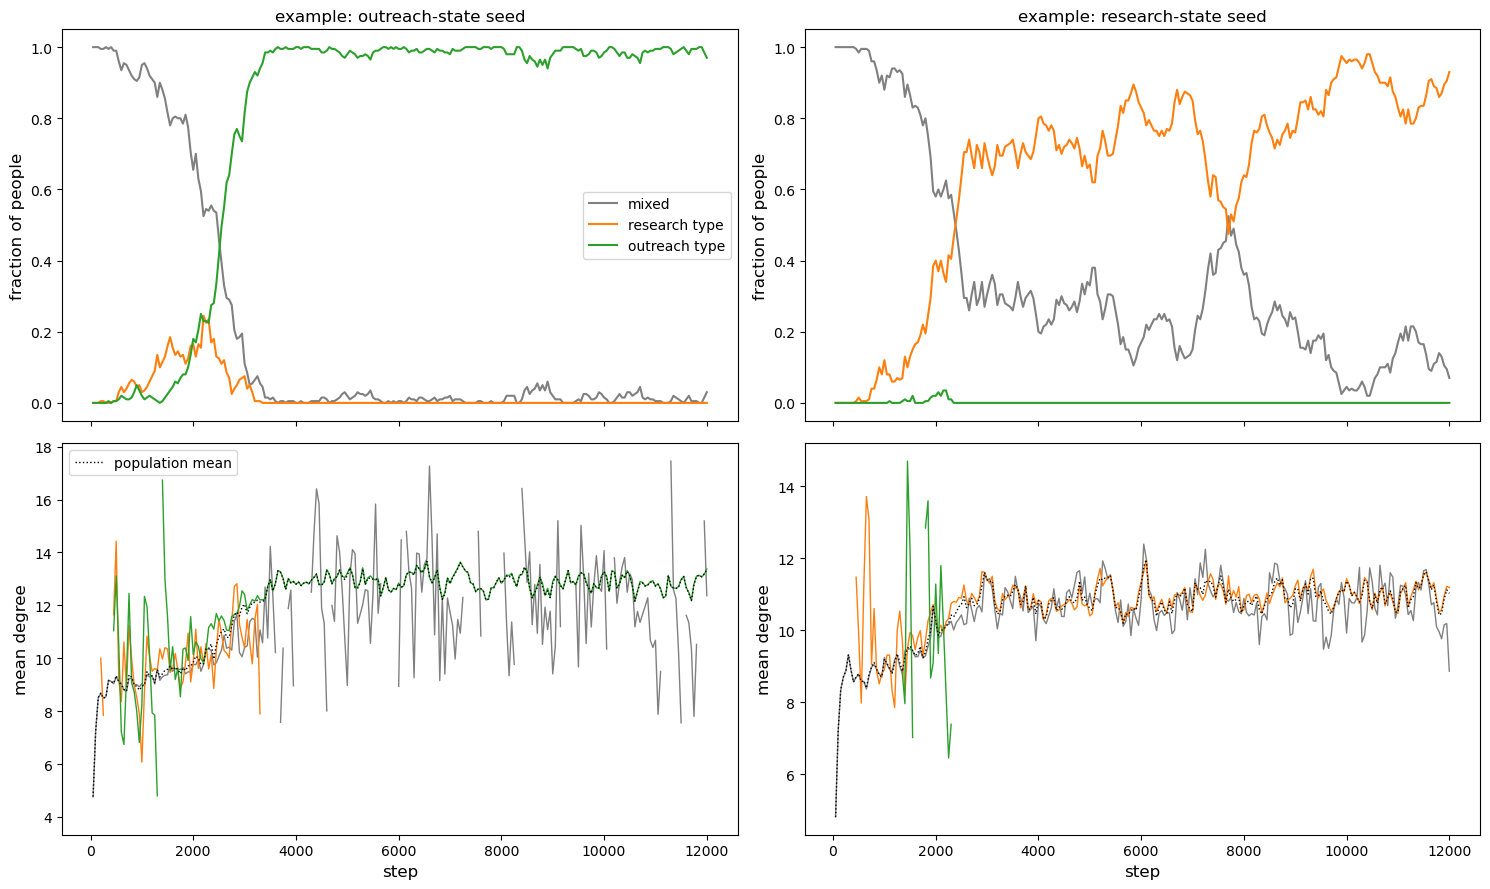

In [5]:
def type_stats(r):
    X, D = r['X'][:-1], r['D'][1:]
    T = types(X)
    frac = np.array([[np.mean(T[k] == j) for j in range(3)] for k in range(len(X))])
    deg = np.array([[D[k][T[k] == j].mean() if np.any(T[k] == j) else np.nan for j in range(3)] for k in range(len(X))])
    # そのタイプ以外の人の平均次数 (有利さの比較相手)
    rest = np.array([[D[k][T[k] != j].mean() if np.any(T[k] != j) else np.nan for j in range(3)] for k in range(len(X))])
    return frac, deg, D.mean(1), rest

fig, axs = plt.subplots(2, 2, figsize=(15, 9), sharex='col')
for col, r in enumerate((ex_o, ex_r)):
    if r is None: axs[0, col].axis('off'); axs[1, col].axis('off'); continue
    frac, deg, mean, _ = type_stats(r)
    for j in range(3):
        axs[0, col].plot(steps[1:], frac[:, j], color=TYPE_COLORS[j], label=TYPE_NAMES[j])
        axs[1, col].plot(steps[1:], deg[:, j], color=TYPE_COLORS[j], lw=1)
    axs[1, col].plot(steps[1:], mean, 'k:', lw=1, label='population mean')
    axs[0, col].set_ylabel('fraction of people', fontsize=12); axs[1, col].set_ylabel('mean degree', fontsize=12)
    axs[1, col].set_xlabel('step', fontsize=12)
    axs[0, col].set_title(['example: outreach-state seed', 'example: research-state seed'][col], fontsize=12)
axs[0, 0].legend(fontsize=10); axs[1, 0].legend(fontsize=10)
plt.tight_layout(); plt.show()

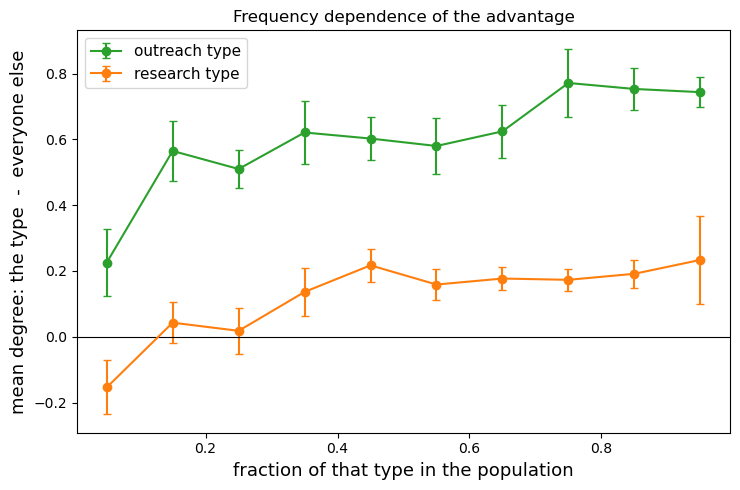

fraction | outreach-type advantage | research-type advantage
  ~0.05  | +0.23 ± 0.10  | -0.15 ± 0.08
  ~0.15  | +0.56 ± 0.09  | +0.04 ± 0.06
  ~0.25  | +0.51 ± 0.06  | +0.02 ± 0.07
  ~0.35  | +0.62 ± 0.10  | +0.14 ± 0.07
  ~0.45  | +0.60 ± 0.07  | +0.22 ± 0.05
  ~0.55  | +0.58 ± 0.08  | +0.16 ± 0.05
  ~0.65  | +0.62 ± 0.08  | +0.18 ± 0.03
  ~0.75  | +0.77 ± 0.10  | +0.17 ± 0.03
  ~0.85  | +0.75 ± 0.06  | +0.19 ± 0.04
  ~0.95  | +0.74 ± 0.05  | +0.23 ± 0.13


In [6]:
# 全シードをまとめ、タイプの割合ごとに「そのタイプの平均次数 − それ以外の人の平均次数」を見る
# (集団平均と比べると、タイプが多数派になるほど差が自動的に0に近づくので使わない)
fr, adv, fr2, adv2 = [], [], [], []
for r in runs:
    frac, deg, mean, rest = type_stats(r)
    ok = ~np.isnan(deg[:, 2]) & ~np.isnan(rest[:, 2]); fr.append(frac[ok, 2]); adv.append(deg[ok, 2] - rest[ok, 2])
    ok = ~np.isnan(deg[:, 1]) & ~np.isnan(rest[:, 1]); fr2.append(frac[ok, 1]); adv2.append(deg[ok, 1] - rest[ok, 1])
fr, adv, fr2, adv2 = map(np.concatenate, (fr, adv, fr2, adv2))
bins = np.linspace(0, 1, 11)
def binned(f, a):
    idx = np.digitize(f, bins) - 1
    return np.array([a[idx == b].mean() if np.sum(idx == b) >= 5 else np.nan for b in range(10)]), \
           np.array([a[idx == b].std() / np.sqrt(max(np.sum(idx == b), 1)) for b in range(10)])
mid = (bins[:-1] + bins[1:]) / 2
fig, ax = plt.subplots(figsize=(7.5, 5))
for f, a, colr, name in ((fr, adv, LC['outreach'], 'outreach type'), (fr2, adv2, LC['research'], 'research type')):
    m, se = binned(f, a)
    ax.errorbar(mid, m, yerr=se, color=colr, marker='o', capsize=3, label=name)
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('fraction of that type in the population', fontsize=13)
ax.set_ylabel('mean degree: the type  -  everyone else', fontsize=13)
ax.legend(fontsize=11); ax.set_title('Frequency dependence of the advantage', fontsize=12)
plt.tight_layout(); plt.show()
m, se = binned(fr, adv); m2, se2 = binned(fr2, adv2)
print('fraction | outreach-type advantage | research-type advantage')
for x0, v, e, v2, e2 in zip(mid, m, se, m2, se2):
    print(f'  ~{x0:.2f}  | {v:+.2f} ± {e:.2f}  | {v2:+.2f} ± {e2:.2f}')

## 4. 最終的な有名人の軌跡

最後の評価窓で次数が上位10人の人を「最終的な有名人」とします。その人たちがいつアウトリーチ型に乗り換えたか、次数がどう伸びたかを追います。
あわせて全シードで、**乗り換えの早さ**と**最終的な有名さ**の関係を調べます。乗り換え時刻は、アウトリーチ割合が初めて0.6以上になった時刻です。

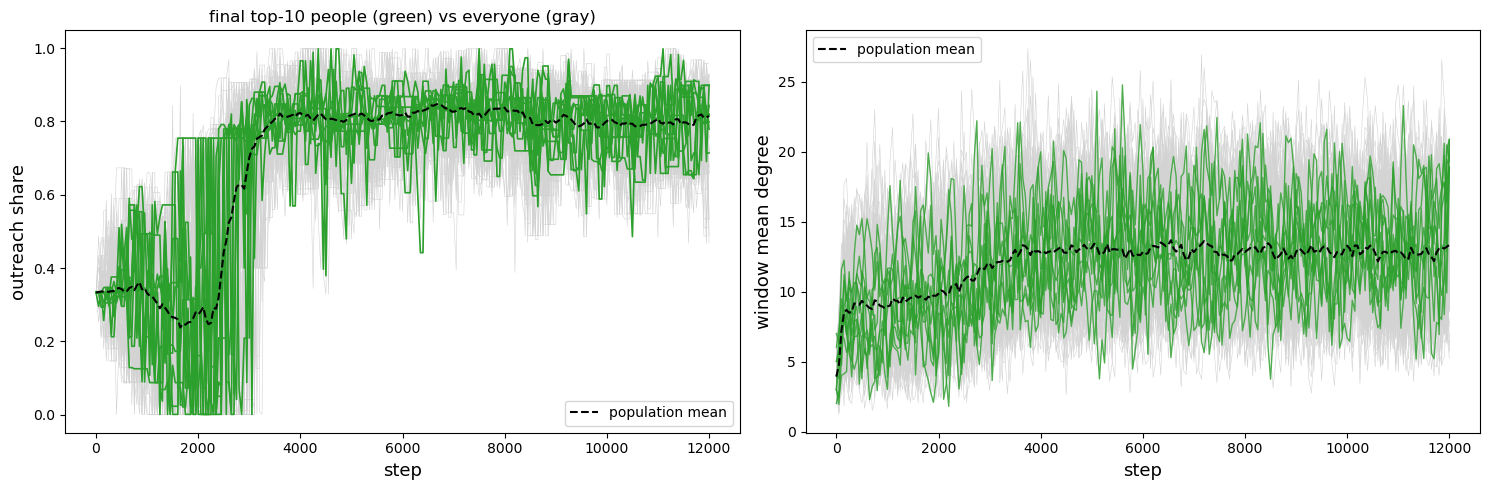

In [7]:
r = ex_o
top = np.argsort(-r['D'][-1])[:10]
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for i in range(r['X'].shape[1]):
    axs[0].plot(steps, r['X'][:, i, 2], color='lightgray', lw=0.4, zorder=1)
    axs[1].plot(steps, r['D'][:, i], color='lightgray', lw=0.4, zorder=1)
for i in top:
    axs[0].plot(steps, r['X'][:, i, 2], color=LC['outreach'], lw=1.2, zorder=2)
    axs[1].plot(steps, r['D'][:, i], color=LC['outreach'], lw=1.0, alpha=0.8, zorder=2)
axs[0].plot(steps, r['X'].mean(1)[:, 2], 'k--', lw=1.5, zorder=3, label='population mean')
axs[1].plot(steps, r['D'].mean(1), 'k--', lw=1.5, zorder=3, label='population mean')
axs[0].set_ylabel('outreach share', fontsize=13); axs[1].set_ylabel('window mean degree', fontsize=13)
for ax in axs: ax.set_xlabel('step', fontsize=13); ax.legend(fontsize=10)
axs[0].set_title('final top-10 people (green) vs everyone (gray)', fontsize=12)
plt.tight_layout(); plt.show()

In [8]:
from scipy.stats import spearmanr
rows = []
for s, r in enumerate(runs):
    if r['state'] != 'outreach': continue
    X = r['X']; N = X.shape[1]
    adopt = np.array([np.argmax(X[:, i, 2] >= 0.6) if np.any(X[:, i, 2] >= 0.6) else n_rec for i in range(N)])
    final = r['D'][-20:].mean(0)                          # 最後の1000ステップの平均次数
    rank = final.argsort().argsort() / (N - 1)
    # 最後の 1000 ステップずっとアウトリーチ型だったか
    stay = (X[-20:, :, 2] >= 0.6).all(0)
    for i in range(N):
        rows.append(dict(seed=s, node=i, adopt_step=adopt[i] * TAU, final_degree=final[i], final_rank=rank[i],
                         final_x3=X[-1, i, 2], final_x1=X[-1, i, 0], outreach_at_end=stay[i]))
nodes = pd.DataFrame(rows)
adopters = nodes[nodes.adopt_step < n_rec * TAU]
rho, pv = spearmanr(adopters.adopt_step, adopters.final_rank)
print(f'adoption time vs final fame rank: Spearman rho = {rho:.2f} (p = {pv:.1g}), n = {len(adopters)}')
# 最終状態での配分と有名さ
for col in ('final_x3', 'final_x1'):
    rr, pp = spearmanr(nodes[col], nodes.final_rank)
    print(f'{col} vs final fame rank: rho = {rr:.2f} (p = {pp:.1g})')
nodes['fame_group'] = pd.qcut(nodes.final_rank, [0, 0.5, 0.9, 1.0], labels=['bottom 50%', 'middle 40%', 'top 10%'])
display(nodes.groupby('fame_group', observed=True)[['adopt_step', 'final_degree', 'final_x1', 'final_x3']].mean().round(3))

adoption time vs final fame rank: Spearman rho = -0.03 (p = 0.1), n = 2400
final_x3 vs final fame rank: rho = -0.03 (p = 0.1)
final_x1 vs final fame rank: rho = 0.04 (p = 0.09)


,adopt_step,final_degree,final_x1,final_x3
fame_group,,,,
bottom 50%,1693.833,11.900,0.151,0.816
middle 40%,1657.396,13.475,0.158,0.808
top 10%,1643.125,14.913,0.152,0.817


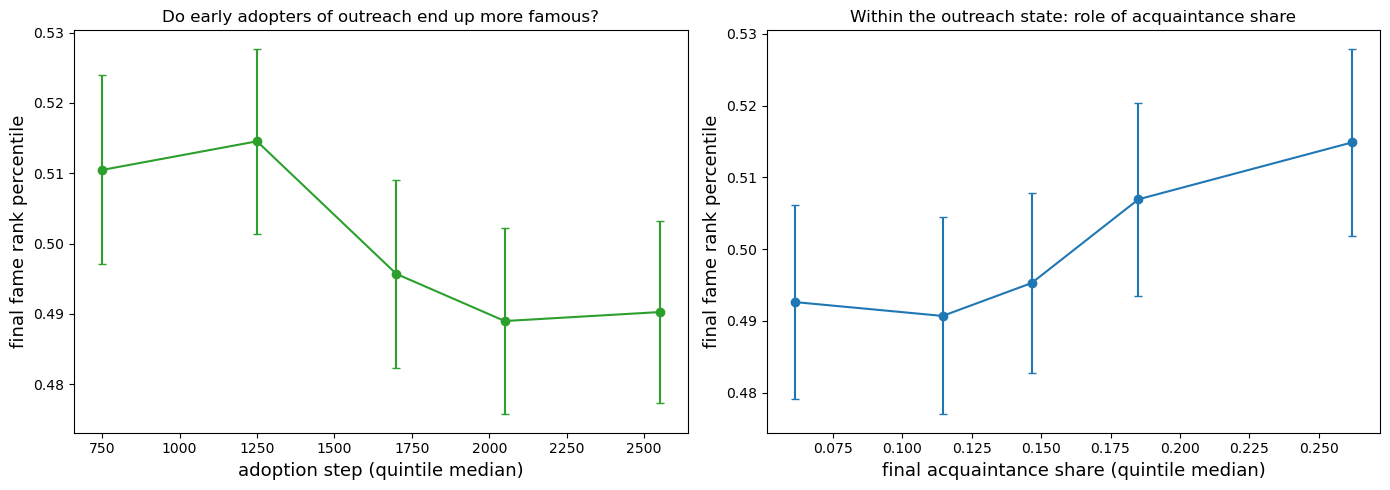

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
q = pd.qcut(adopters.adopt_step.rank(method='first'), 5, labels=False)
g = adopters.groupby(q)
axs[0].errorbar(g.adopt_step.median(), g.final_rank.mean(), yerr=g.final_rank.sem(), marker='o', capsize=3, color=LC['outreach'])
axs[0].set_xlabel('adoption step (quintile median)', fontsize=13); axs[0].set_ylabel('final fame rank percentile', fontsize=13)
axs[0].set_title('Do early adopters of outreach end up more famous?', fontsize=12)
q2 = pd.qcut(nodes.final_x1, 5, duplicates='drop')
g2 = nodes.groupby(q2, observed=True)
axs[1].errorbar(g2.final_x1.median(), g2.final_rank.mean(), yerr=g2.final_rank.sem(), marker='o', capsize=3, color=LC['acquaint'])
axs[1].set_xlabel('final acquaintance share (quintile median)', fontsize=13); axs[1].set_ylabel('final fame rank percentile', fontsize=13)
axs[1].set_title('Within the outreach state: role of acquaintance share', fontsize=12)
plt.tight_layout(); plt.show()

### 4.1 有名さはどれくらい続くか

アウトリーチ型に落ち着いた後(最後の6000ステップ)で、ある時点の次数の順位と、ラグだけ後の順位の相関を測ります。相関がすぐ0に落ちるなら、有名さは一時的で、入れ替わりが激しいことになります。

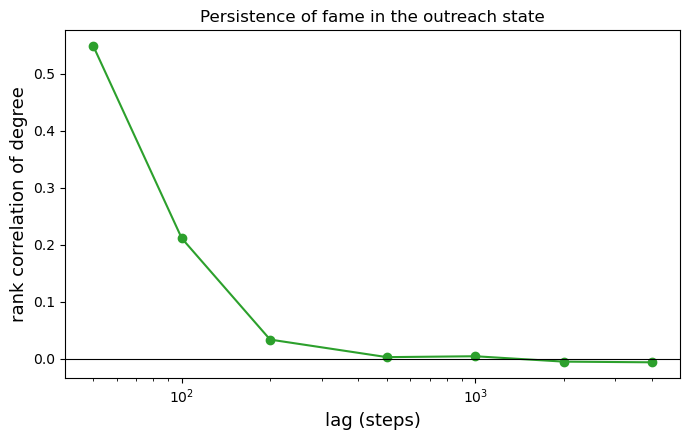

lag    50 steps: rank correlation 0.55
lag   100 steps: rank correlation 0.21
lag   200 steps: rank correlation 0.03
lag   500 steps: rank correlation 0.00
lag  1000 steps: rank correlation 0.00
lag  2000 steps: rank correlation -0.01
lag  4000 steps: rank correlation -0.01
reference: link lifetime 1/mu = 50.0 steps


In [10]:
from scipy.stats import spearmanr
lags = [1, 2, 4, 10, 20, 40, 80]
st = n_rec // 2                                   # 後半だけを使う
acc = {L: [] for L in lags}
for r in runs:
    if r['state'] != 'outreach': continue
    D = r['D']
    for L in lags:
        acc[L].append(np.mean([spearmanr(D[k], D[k + L])[0] for k in range(st, n_rec - L, 5)]))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(np.array(lags) * TAU, [np.mean(acc[L]) for L in lags], 'o-', color=LC['outreach'])
ax.axhline(0, color='k', lw=0.8); ax.set_xscale('log')
ax.set_xlabel('lag (steps)', fontsize=13); ax.set_ylabel('rank correlation of degree', fontsize=13)
ax.set_title('Persistence of fame in the outreach state', fontsize=12)
plt.tight_layout(); plt.show()
for L in lags: print(f'lag {L * TAU:5d} steps: rank correlation {np.mean(acc[L]):.2f}')
print('reference: link lifetime 1/mu =', 1 / DEFAULT['mu'], 'steps')

## 5. 勝った戦略の系譜

戦略には ID が付いています。模倣では相手の ID をそのままコピーし、突然変異では親の ID を持つ新しい ID が生まれます。
最後に最も多くの人が使っていた戦略をたどると、均等配分(根)から何回の突然変異を経て、いつ、どの道筋で生まれたかがわかります。
下の図の左は、その祖先の配分の道筋です。右は、各祖先の子孫の戦略を使っている人の割合の推移です。

In [11]:
def descends_from(s_parent, sids, anc_set_cache):
    """各 sid の祖先集合 (キャッシュ付き)"""
    out = []
    for sd in sids:
        if sd not in anc_set_cache:
            anc_set_cache[sd] = set(lineage(s_parent, sd))
        out.append(anc_set_cache[sd])
    return out

lin_rows = []
for s, r in enumerate(runs):
    win = np.bincount(r['SID'][-1]).argmax()
    chain = lineage(r['s_parent'], win)
    r['chain'] = chain
    share_win = np.mean(r['SID'][-1] == win)
    # 最終状態の人のうち、勝った系統 (chain[1] 以降の子孫) に属する割合
    cache = {}
    anc = descends_from(r['s_parent'], r['SID'][-1], cache)
    founder = chain[1] if len(chain) > 1 else chain[0]
    lin_rows.append(dict(seed=s, state=r['state'], n_mutations=len(chain) - 1,
                         founder_born_step=int(r['s_time'][founder]),
                         winner_born_step=int(r['s_time'][win]),
                         share_exact_winner=share_win,
                         share_descending_from_founder=np.mean([founder in a for a in anc]),
                         winner_x=str(np.round(r['s_x'][win].astype(float), 2))))
lin = pd.DataFrame(lin_rows)
display(lin)

,seed,state,n_mutations,founder_born_step,winner_born_step,share_exact_winner,share_descending_from_founder,winner_x
0,0,outreach,16,100,10150,0.115,1.000,[0.1 0. 0.9]
1,1,outreach,26,400,10650,0.110,0.935,[0.2 0. 0.8]
2,2,research,22,1700,10350,0.105,0.360,[0.19 0.8 0.01]
3,3,outreach,24,550,11300,0.085,1.000,[0.09 0. 0.91]
4,4,research,18,350,11000,0.065,1.000,[0.29 0.68 0.03]
5,5,research,12,50,10700,0.100,1.000,[0.12 0.84 0.04]
6,6,outreach,23,700,10250,0.125,1.000,[0.16 0. 0.84]
7,7,outreach,21,50,11150,0.080,1.000,[0.19 0. 0.81]
8,8,outreach,14,300,9550,0.110,1.000,[0.19 0. 0.81]
9,9,outreach,28,100,11400,0.090,1.000,[0.15 0.03 0.82]


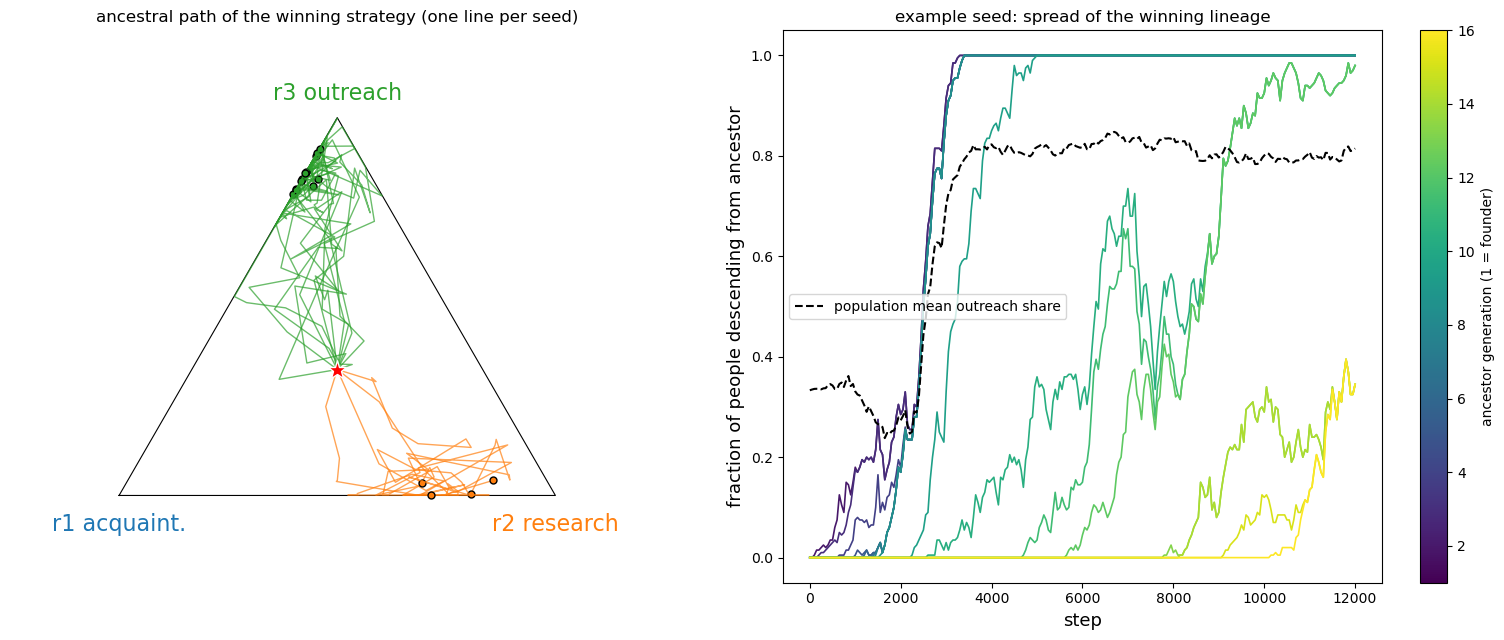

example seed: generations 16
ancestor allocations (every 5th):
  gen   0  born step      0  x = [0.33 0.33 0.33]
  gen   1  born step    100  x = [0.29 0.36 0.35]
  gen   2  born step    200  x = [0.32 0.33 0.35]
  gen   3  born step    650  x = [0.32 0.33 0.35]
  gen   4  born step   1000  x = [0.31 0.24 0.45]
  gen   5  born step   1200  x = [0.37 0.13 0.5 ]
  gen   6  born step   1400  x = [0.45 0.04 0.51]
  gen   7  born step   1450  x = [0.47 0.   0.53]
  gen   8  born step   1550  x = [0.24 0.   0.75]
  gen   9  born step   2250  x = [0.17 0.04 0.79]
  gen  10  born step   2600  x = [0.15 0.   0.85]
  gen  11  born step   4700  x = [0.13 0.   0.87]
  gen  12  born step   5650  x = [0.13 0.   0.87]
  gen  13  born step   7800  x = [0.2 0.  0.8]
  gen  14  born step   8150  x = [0.13 0.   0.86]
  gen  15  born step   9100  x = [0.13 0.   0.87]
  gen  16  born step  10150  x = [0.1 0.  0.9]


In [12]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6.5))
tri_axes(axs[0])
for s, r in enumerate(runs):
    xs = r['s_x'][r['chain']]
    col = LC['outreach'] if r['state'] == 'outreach' else LC['research'] if r['state'] == 'research' else 'gray'
    axs[0].plot(*tern(xs), '-', color=col, lw=1, alpha=0.7)
    axs[0].plot(*tern(xs[-1]), 'o', color=col, ms=5, mec='k')
axs[0].plot(*tern([1/3, 1/3, 1/3]), 'r*', ms=14, mec='w')
axs[0].set_title('ancestral path of the winning strategy (one line per seed)', fontsize=12)

# 例のシード: 勝った系統の各祖先について、その子孫を使っている人の割合
r = ex_o; chain = r['chain']; cache = {}
share = np.zeros((n_rec, len(chain)))
for k in range(n_rec):
    anc = descends_from(r['s_parent'], r['SID'][k], cache)
    for a_i, a in enumerate(chain):
        share[k, a_i] = np.mean([a in s_ for s_ in anc])
cm = plt.cm.viridis(np.linspace(0, 1, len(chain)))
for a_i in range(1, len(chain)):
    axs[1].plot(steps, share[:, a_i], color=cm[a_i], lw=1.2)
axs[1].plot(steps, r['X'].mean(1)[:, 2], 'k--', lw=1.5, label='population mean outreach share')
sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(1, len(chain) - 1))
plt.colorbar(sm, ax=axs[1], label='ancestor generation (1 = founder)')
axs[1].set_xlabel('step', fontsize=13); axs[1].set_ylabel('fraction of people descending from ancestor', fontsize=13)
axs[1].set_title('example seed: spread of the winning lineage', fontsize=12); axs[1].legend(fontsize=10)
plt.tight_layout(); plt.show()
print('example seed: generations', len(chain) - 1)
print('ancestor allocations (every 5th):')
for g_i in range(0, len(chain), max(1, len(chain) // 10)):
    a = chain[g_i]; print(f'  gen {g_i:3d}  born step {r["s_time"][a]:6d}  x = {np.round(r["s_x"][a], 2)}')

## 6. 最終状態のネットワーク(例)

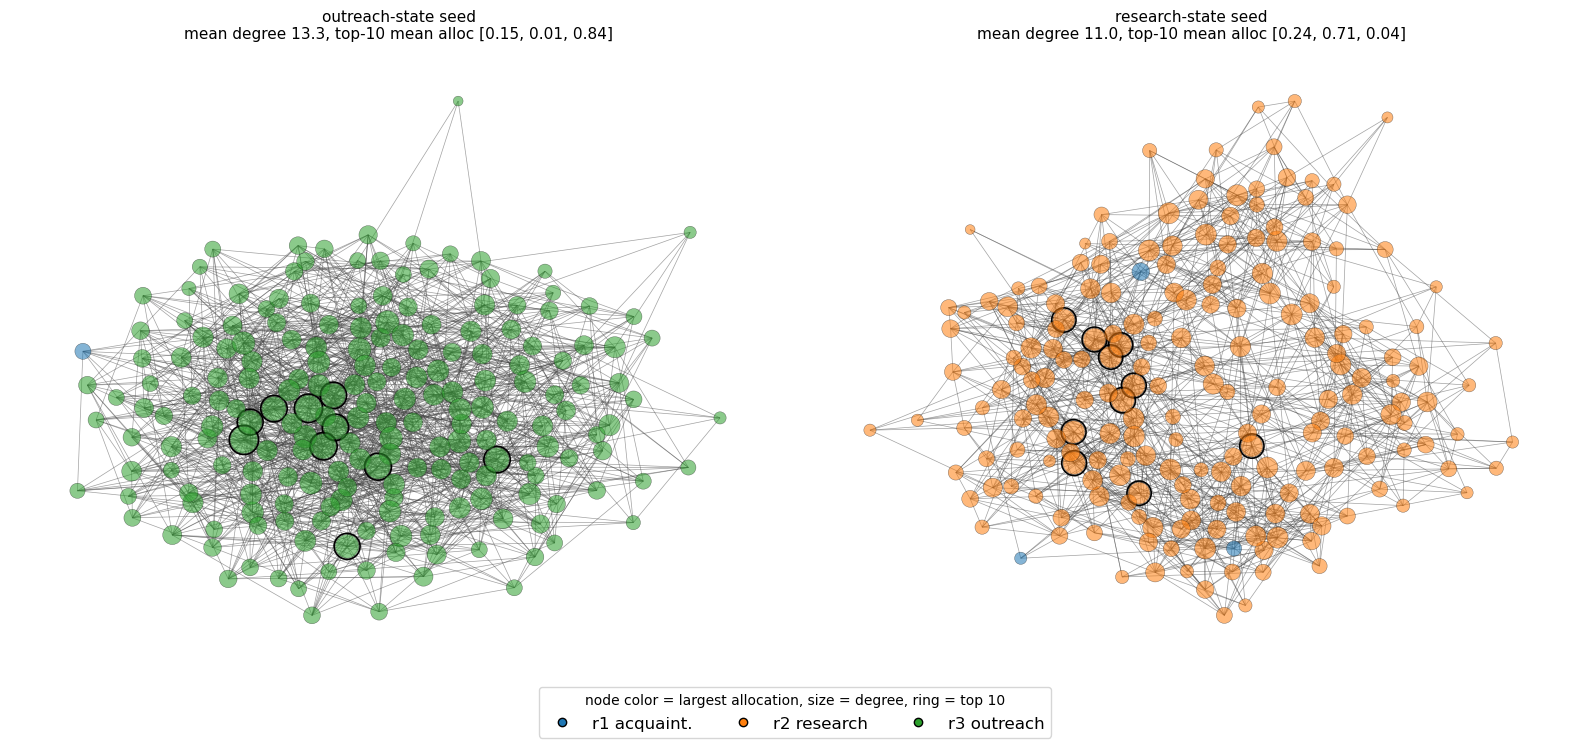

In [13]:
def draw_final(ax, r, title):
    N = r['X'].shape[1]
    G = nx.Graph(); G.add_nodes_from(range(N)); G.add_edges_from(map(tuple, r['edges'].astype(int)))
    pos = nx.spring_layout(G, seed=0, k=1.2 / np.sqrt(N), iterations=200)
    deg = np.array([G.degree(i) for i in range(N)])
    col = [LC[KEYS[k]] for k in r['X'][-1].argmax(1)]
    nx.draw_networkx_edges(G, pos, ax=ax, width=0.5, alpha=0.5, edge_color='#444444')
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=8 + 14 * deg, node_color=col, linewidths=0.3, edgecolors='k', alpha=0.55)
    top = np.argsort(-deg)[:10]
    ax.scatter(*np.array([pos[i] for i in top]).T, s=8 + 14 * deg[top] + 60, facecolors='none', edgecolors='k', linewidths=1.2)
    ax.set_title(f'{title}\nmean degree {deg.mean():.1f}, top-10 mean alloc {np.round(r["X"][-1][top].mean(0), 2).tolist()}', fontsize=11)
    ax.axis('off')

fig, axs = plt.subplots(1, 2, figsize=(16, 7.5))
draw_final(axs[0], ex_o, 'outreach-state seed')
if ex_r is not None: draw_final(axs[1], ex_r, 'research-state seed')
else: axs[1].axis('off')
fig.legend(handles=[Line2D([], [], marker='o', ls='', mfc=LC[k], mec='k', label=NAMES[k]) for k in KEYS],
           loc='lower center', ncol=3, fontsize=12, title='node color = largest allocation, size = degree, ring = top 10')
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

## まとめ(16シード、12000ステップ)

**行き先**
- 16シード中12シードがアウトリーチ型、4シードが研究型の状態に落ち着いた。
- アウトリーチ型の集団平均は (0.15, 0.04, 0.81) で、平均次数は 12.8 だった。研究型は (0.24〜0.30, 0.65〜0.71, 0.05) で、平均次数は 10.9 だった。
- 移行は 1200〜4300 ステップで起き、その後は最後まで安定していた。

**有名人が集団を先導する**
- 各時点の有名人(次数上位10%)は、集団よりも先にアウトリーチ割合0.5を超えた。先行の中央値は175ステップ(範囲100〜700)だった。
- アウトリーチを先に使った人が次数を伸ばして有名になり、その隣人がまねて広がる、という順序で移行が進む。

**アウトリーチ型の有利さは、広がっても縮まない**
- アウトリーチ型の有利さは、少数派(約5%)で +0.2、15〜65% で約 +0.6、75%以上で約 +0.75 だった。広がるほど有利さが縮む「ブレーキ」がないので、ほぼ全員に広がる。
- 研究型は、少数派(約5%)では不利(−0.15)で、35%を超えると少し有利(+0.15〜0.2)になる。仲間が多いほど得をする戦略である。
- 研究型の状態が崩れないのは、突然変異1回では閾値(アウトリーチ割合約0.6)を越えられず、途中の配分が不利な谷にあたるためと考えられる。この説明は、モデル2の地形と整合するが、直接は確かめていない。

**最終的に誰が有名になるかは、ほぼ運で決まる**
- アウトリーチ型に落ち着いた後は、最終的な有名さと、アウトリーチに乗り換えた時刻との相関はなかった(順位相関 −0.03)。配分との相関もなかった。上位10%と下位50%の配分はほぼ同じだった。
- 有名さは長続きしない。次数の順位相関は、50ステップ後で 0.55、100ステップ後で 0.21、200ステップ後でほぼ0になった。リンクの寿命 1/μ = 50 ステップと同じ時間スケールである。
- 全員が同じ戦略を使うようになると、戦略では差がつかず、有名さは一時的な運の産物になる。

**勝った戦略の系譜**
- 16シード中14シードで、最終状態の全員が、たった1つの初期の突然変異の子孫だった。残る2シードでも、その子孫は93.5%と36%を占めた。
- その祖先(創始者)は、中央値で開始から約375ステップで生まれていた。最終的な戦略までに、12〜28回の突然変異を経ていた。
- 最後に最も多い戦略そのものは、9500ステップ以降に生まれた新しいもので、占める割合は6〜12%にすぎない。山の頂上付近で、配分は小さな突然変異でゆっくり漂い続けている。
- 例のシードでは、まず研究を減らし(1000〜1450ステップ)、次にアウトリーチを一気に増やして(1550ステップ)谷を越えていた。
